# Notebook 02 - Data and features (Steps 3-7)

**Goal:** turn the raw Lending Club file into one clean table, `clean.parquet`, that notebook 03 can model.

Rules this notebook follows (every one is checked by code below, not just claimed):

1. The **split is made before any exploring**, so nothing we look at is chosen with the test period in mind.
2. EDA and every decision about data use **training rows only**.
3. Only information known **at application time** is kept as a feature.
4. Anything that *learns a number from data* (median, mean, category list) is **not** done here. It goes inside the model pipeline in notebook 03 and is fitted on training rows only.

Every number quoted in this notebook is printed by a code cell. Markdown cells only explain *what we do and why*.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

RANDOM_SEED = 42
ROOT = Path("..")
RAW_FILE = ROOT / "data/raw/accepted_2007_to_2018Q4.csv.gz"
CLEAN_FILE = ROOT / "data/processed/clean.parquet"
FEATURES_FILE = ROOT / "data/processed/features.json"
MANIFEST_FILE = ROOT / "artifacts/split_manifest.json"
FIG_DIR = ROOT / "artifacts/figures"
for folder in [CLEAN_FILE.parent, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.3f}".format)
pd.set_option("display.width", 140)

def save_fig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

if not RAW_FILE.exists():
    raise FileNotFoundError(
        "Put accepted_2007_to_2018Q4.csv.gz in data/raw/ "
        "(Kaggle: wordsforthewise/lending-club). See README.md.")

## Step 3 - Understand the data

### 3.1 How big is the raw file?
We read only the header first (cheap) to see how many columns exist before loading anything.

In [2]:
header = pd.read_csv(RAW_FILE, nrows=0)
print("Number of columns in the raw file:", len(header.columns))

Number of columns in the raw file: 151


### 3.2 Data dictionary - which columns may we use?

Out of the raw columns we keep only those a lender **already knows when it decides** on the application. For each one we write down *why* it is known at that moment. This is a judgement we make by reading what the column means; in 4.4 we then test the judgement with code.

**Table 1.** Data dictionary of the columns we load.

In [3]:
# (column, meaning, why it is known at application time)
DICTIONARY = [
    ("loan_amnt",            "Amount the borrower asked for",              "Entered on the application"),
    ("term",                 "Loan length: 36 or 60 months",               "Chosen by the borrower"),
    ("int_rate",             "Interest rate offered (%)",                  "Set by Lending Club when it decides"),
    ("installment",          "Monthly payment",                            "Computed from amount, rate and term"),
    ("grade",                "Lending Club risk grade (A-G)",              "Assigned by Lending Club when it decides"),
    ("sub_grade",            "Finer grade (A1-G5)",                        "Assigned by Lending Club when it decides"),
    ("emp_length",           "Years in current job",                       "Entered on the application"),
    ("home_ownership",       "RENT / MORTGAGE / OWN",                      "Entered on the application"),
    ("annual_inc",           "Self-reported yearly income",                "Entered on the application"),
    ("verification_status",  "Was the income verified?",                   "Decided during underwriting"),
    ("purpose",              "Why the borrower wants the loan",            "Entered on the application"),
    ("dti",                  "Debt payments / monthly income (%)",         "Computed from the credit report at application"),
    ("delinq_2yrs",          "Late payments in the last 2 years",          "Credit report at application"),
    ("earliest_cr_line",     "Month the first credit line was opened",     "Credit report at application"),
    ("fico_range_low",       "FICO score, lower end of band",              "Credit report at application"),
    ("fico_range_high",      "FICO score, upper end of band",              "Credit report at application"),
    ("inq_last_6mths",       "Credit enquiries in last 6 months",          "Credit report at application"),
    ("open_acc",             "Open credit lines",                          "Credit report at application"),
    ("pub_rec",              "Derogatory public records",                  "Credit report at application"),
    ("revol_bal",            "Revolving balance",                          "Credit report at application"),
    ("revol_util",           "Revolving credit used (%)",                  "Credit report at application"),
    ("total_acc",            "Total credit lines ever",                    "Credit report at application"),
    ("mort_acc",             "Number of mortgage accounts",                "Credit report at application"),
    ("pub_rec_bankruptcies", "Public-record bankruptcies",                 "Credit report at application"),
    ("application_type",     "Individual or joint application",           "Entered on the application"),
    ("issue_d",              "Month the loan was issued",                  "Used ONLY to order/split rows, never as a feature"),
    ("id",                   "Loan id",                                    "Used ONLY to audit the split, never as a feature"),
    ("loan_status",          "Outcome of the loan",                        "This is the TARGET source, never a feature"),
]
dictionary = pd.DataFrame(DICTIONARY, columns=["column", "meaning", "why_known_at_application"])
print(f"{len(dictionary)} columns kept out of {len(header.columns)}")
dictionary

28 columns kept out of 151


,column,meaning,why_known_at_application
0,loan_amnt,Amount the borrower asked for,Entered on the application
1,term,Loan length: 36 or 60 months,Chosen by the borrower
2,int_rate,Interest rate offered (%),Set by Lending Club when it decides
3,installment,Monthly payment,"Computed from amount, rate and term"
4,grade,Lending Club risk grade (A-G),Assigned by Lending Club when it decides
5,sub_grade,Finer grade (A1-G5),Assigned by Lending Club when it decides
6,emp_length,Years in current job,Entered on the application
7,home_ownership,RENT / MORTGAGE / OWN,Entered on the application
8,annual_inc,Self-reported yearly income,Entered on the application
9,verification_status,Was the income verified?,Decided during underwriting


**Table 2.** Four columns we load *on purpose* to test the idea of leakage in 4.4. They describe what happens **after** the loan starts, so a lender could never use them to approve or reject. They will be dropped.

| Column | What it holds |
|---|---|
| `total_pymnt` | Total money paid back so far |
| `recoveries` | Money recovered after a charge-off |
| `last_pymnt_amnt` | Size of the last payment received |
| `last_fico_range_high` | FICO score pulled again *during* the loan |

In [4]:
LEAK_DEMO = ["total_pymnt", "recoveries", "last_pymnt_amnt", "last_fico_range_high"]
use_cols = list(dictionary["column"]) + LEAK_DEMO
raw = pd.read_csv(RAW_FILE, usecols=use_cols, dtype={"id": "string"}, low_memory=False)
print("Rows loaded:", f"{len(raw):,}", "| columns:", raw.shape[1])
raw.head(3).T

Rows loaded: 2,260,701 | columns: 32


,0,1,2
id,68407277,68355089,68341763
loan_amnt,"3,600.000","24,700.000","20,000.000"
term,36 months,36 months,60 months
int_rate,13.990,11.990,10.780
installment,123.030,820.280,432.660
grade,C,C,B
sub_grade,C4,C1,B4
emp_length,10+ years,10+ years,10+ years
home_ownership,MORTGAGE,MORTGAGE,MORTGAGE
annual_inc,"55,000.000","65,000.000","63,000.000"


### 3.3 What is the outcome of each loan?
A loan only has a *known* result once it ended. We count each status.

**Table 3.** Loans by `loan_status`.

In [5]:
status_table = raw["loan_status"].value_counts(dropna=False).to_frame("loans")
status_table["share_%"] = 100 * status_table["loans"] / len(raw)
status_table

,loans,share_%
loan_status,,
Fully Paid,1076751,47.629
Current,878317,38.852
Charged Off,268559,11.879
Late (31-120 days),21467,0.950
In Grace Period,8436,0.373
Late (16-30 days),4349,0.192
Does not meet the credit policy. Status:Fully Paid,1988,0.088
Does not meet the credit policy. Status:Charged Off,761,0.034
Default,40,0.002


In [6]:
resolved = status_table.loc[["Fully Paid", "Charged Off"], "loans"].sum()
print(f"Only {resolved:,} of {len(raw):,} loans ({100*resolved/len(raw):.1f}%) are clearly 'Fully Paid' or 'Charged Off'.")
print("All other statuses (Current, Late, ...) have no final outcome yet, so we cannot label them.")

Only 1,345,310 of 2,260,701 loans (59.5%) are clearly 'Fully Paid' or 'Charged Off'.
All other statuses (Current, Late, ...) have no final outcome yet, so we cannot label them.


### 3.4 Define the target
`default = 1` if `Charged Off`, `0` if `Fully Paid`. We keep only these two statuses. Rows with other statuses are removed because we do not know how they will end.

In [7]:
n_before = len(raw)
df = raw[raw["loan_status"].isin(["Fully Paid", "Charged Off"])].copy()
df["default"] = (df["loan_status"] == "Charged Off").astype(int)
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")

print(f"Rows before: {n_before:,} | after keeping labelled loans: {len(df):,}")
print(f"Default rate overall: {df['default'].mean():.3f}")
print("Issue dates run from", df["issue_d"].min().date(), "to", df["issue_d"].max().date())

Rows before: 2,260,701 | after keeping labelled loans: 1,345,310
Default rate overall: 0.200
Issue dates run from 2007-06-01 to 2018-12-01


## Step 4 - Split the data (before exploring anything)

We split **by time**: loans issued before `2016-01-01` are **train**, loans issued on or after are **test**. This cutoff is fixed and shared by all groups that use this dataset, so everyone gets the identical split.

*Why not a random split?* A lender scores *future* applicants using a model built on *past* loans. A random split lets the model peek at loans from the same months as the test loans, which is not how it will be used. We will measure how much this matters in notebook 03 (section 9.5) rather than just assert it.

In [8]:
CUTOFF = pd.Timestamp("2016-01-01")

df = df.sort_values(["issue_d", "id"]).reset_index(drop=True)
df["split"] = np.where(df["issue_d"] < CUTOFF, "train", "test")

train = df[df["split"] == "train"]
test = df[df["split"] == "test"]

# Guard against look-ahead: every training loan is older than every test loan.
assert train["issue_d"].max() < test["issue_d"].min()

print(f"train: {len(train):,} loans, {train['issue_d'].min():%b %Y} to {train['issue_d'].max():%b %Y}, default rate {train['default'].mean():.3f}")
print(f"test : {len(test):,} loans, {test['issue_d'].min():%b %Y} to {test['issue_d'].max():%b %Y}, default rate {test['default'].mean():.3f}")

train: 826,604 loans, Jun 2007 to Dec 2015, default rate 0.184
test : 518,706 loans, Jan 2016 to Dec 2018, default rate 0.224


### 4.1 Save an auditable record of the split
Other groups can compare this file with theirs. The fingerprint is an MD5 hash of the sorted training loan ids: if two groups have the same fingerprint, they have the same training set.

In [9]:
manifest = {
    "cutoff_issue_d": str(CUTOFF.date()),
    "rule": "train = issue_d < cutoff, test = issue_d >= cutoff",
    "n_train": int(len(train)),
    "n_test": int(len(test)),
    "default_rate_train": round(float(train["default"].mean()), 4),
    "default_rate_test": round(float(test["default"].mean()), 4),
    "train_ids_md5": hashlib.md5(",".join(train["id"]).encode()).hexdigest(),
}
MANIFEST_FILE.write_text(json.dumps(manifest, indent=2))
print(json.dumps(manifest, indent=2))

{
  "cutoff_issue_d": "2016-01-01",
  "rule": "train = issue_d < cutoff, test = issue_d >= cutoff",
  "n_train": 826604,
  "n_test": 518706,
  "default_rate_train": 0.1843,
  "default_rate_test": 0.2241,
  "train_ids_md5": "ab7caf58adc46673ead00bb6fb2ba124"
}


### 4.2 How trustworthy is the test period's label?
A loan issued late in the data may simply not have finished yet. Such loans are missing from our labelled data, so the loans we *do* see are a selected subset and the default rate we compute may be biased. We do not assume in which direction; we measure.

We check this directly: for every issue year, what share of **all** loans already has a final outcome, and what is the default rate among those?
This is a *diagnostic about the labels*; no feature or model choice is made from it.

**Table 4.** Share of loans with a final outcome, by issue year.

In [10]:
all_loans = raw.dropna(subset=["issue_d"]).copy()
all_loans["year"] = pd.to_datetime(all_loans["issue_d"], format="%b-%Y").dt.year
all_loans["resolved"] = all_loans["loan_status"].isin(["Fully Paid", "Charged Off"])
all_loans["default"] = (all_loans["loan_status"] == "Charged Off").astype(float)
all_loans.loc[~all_loans["resolved"], "default"] = np.nan

maturity = all_loans.groupby("year").agg(
    loans_issued=("resolved", "size"),
    share_resolved=("resolved", "mean"),
    default_rate_among_resolved=("default", "mean"),
)
maturity.index = maturity.index.astype(str)   # show years as 2015, not 2,015
maturity

,loans_issued,share_resolved,default_rate_among_resolved
year,,,
2007,603,0.416,0.179
2008,2393,0.653,0.158
2009,5281,0.893,0.126
2010,12537,0.920,0.129
2011,21721,1.000,0.152
2012,53367,1.000,0.162
2013,134814,1.000,0.156
2014,235629,0.947,0.184
2015,421095,0.892,0.202


In [11]:
test_years = maturity.loc[maturity.index.astype(int) >= CUTOFF.year]
worst_year = test_years["share_resolved"].idxmin()
print(f"In the test period, the year with the lowest share of finished loans is {worst_year}: "
      f"only {test_years.loc[worst_year, 'share_resolved']:.1%} are resolved.")
print(f"Its default rate among resolved loans is {test_years.loc[worst_year, 'default_rate_among_resolved']:.3f}, "
      f"versus {test_years['default_rate_among_resolved'].max():.3f} for the highest test year.")
print(f"Test default rate over all test years is {test['default'].mean():.3f}, but the last year is measured on a small, "
      "early-finishing subset, so it is not the true rate for that year.")
print("Action -> keep this as a stated limitation in the conclusion of notebook 03; do not claim the test default rate is exact.")

In the test period, the year with the lowest share of finished loans is 2018: only 11.4% are resolved.
Its default rate among resolved loans is 0.157, versus 0.233 for the highest test year.
Test default rate over all test years is 0.224, but the last year is measured on a small, early-finishing subset, so it is not the true rate for that year.
Action -> keep this as a stated limitation in the conclusion of notebook 03; do not claim the test default rate is exact.


### 4.3 Leakage smell test (training rows only)

*Leakage* means using information the lender would not have at decision time. A quick numerical smell test: score every numeric column **alone** by ROC-AUC against the target (0.5 = useless, 1.0 = perfect; we use `max(AUC, 1-AUC)` so direction does not matter). A column that predicts almost perfectly on its own is suspicious.

Missing values are filled with the training median for this test only (it is a one-off diagnostic, not part of the model).

**Figure 1.** Single-column ROC-AUC on training rows. Red = columns we believe are post-origination (Table 2); blue = application-time columns.

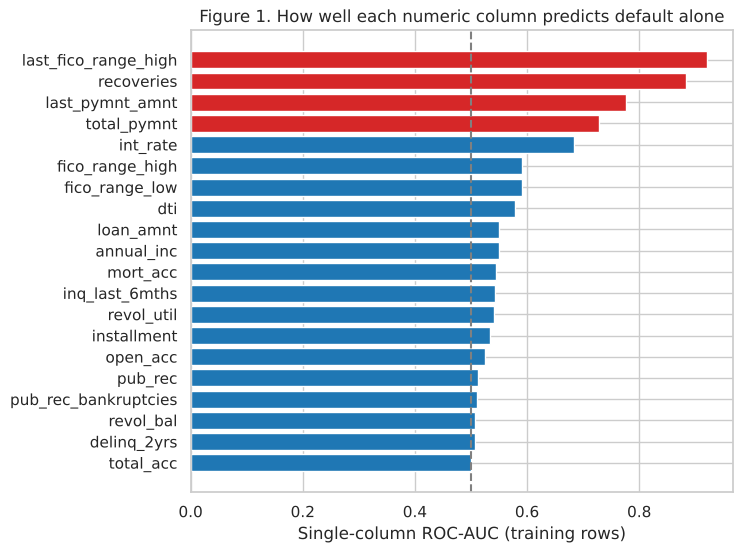

In [12]:
numeric_cols = [c for c in train.columns
                if c not in ["default", "id"] and pd.api.types.is_numeric_dtype(train[c])]
auc_alone = {}
for col in numeric_cols:
    values = train[col].fillna(train[col].median())
    auc = roc_auc_score(train["default"], values)
    auc_alone[col] = max(auc, 1 - auc)
auc_alone = pd.Series(auc_alone).sort_values()

colors = ["tab:red" if c in LEAK_DEMO else "tab:blue" for c in auc_alone.index]
plt.figure(figsize=(7, 6))
plt.barh(auc_alone.index, auc_alone.values, color=colors)
plt.axvline(0.5, color="gray", linestyle="--")
plt.xlabel("Single-column ROC-AUC (training rows)")
plt.title("Figure 1. How well each numeric column predicts default alone")
save_fig("01_leakage_smell_test")
plt.show()

In [13]:
leak_auc = auc_alone[LEAK_DEMO]
app_auc = auc_alone.drop(LEAK_DEMO)
print("Post-origination columns:")
print(leak_auc.sort_values(ascending=False).round(3).to_string())
print()
print(f"Best application-time column: {app_auc.idxmax()} with AUC {app_auc.max():.3f}")
print(f"Strongest post-origination column: {leak_auc.idxmax()} with AUC {leak_auc.max():.3f}")
print()
print("Action -> drop all four post-origination columns. If a model scored far above the best "
      "application-time column alone, we would suspect one of them had survived.")

Post-origination columns:
last_fico_range_high   0.921
recoveries             0.884
last_pymnt_amnt        0.777
total_pymnt            0.728

Best application-time column: int_rate with AUC 0.684
Strongest post-origination column: last_fico_range_high with AUC 0.921

Action -> drop all four post-origination columns. If a model scored far above the best application-time column alone, we would suspect one of them had survived.


In [14]:
# Drop the leakage columns now; they are never used again.
df = df.drop(columns=LEAK_DEMO + ["loan_status"])
train = df[df["split"] == "train"]
test = df[df["split"] == "test"]
print("Columns left:", df.shape[1])

Columns left: 29


## Step 5 - Exploratory data analysis (training rows only)

Every plot below uses `train`. The test rows are not touched.

### 5.1 Class balance and drift over time

**Figure 2.** Left: how many training loans default. Right: the default rate by issue year inside the training period.

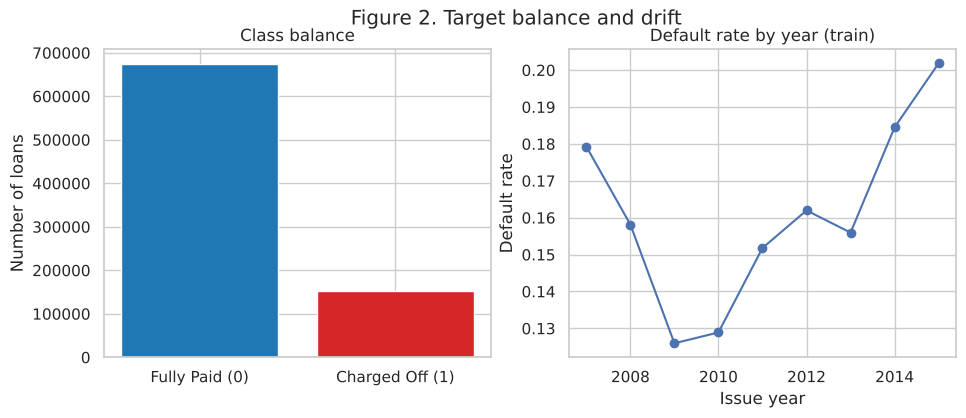

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

counts = train["default"].value_counts().sort_index()
ax[0].bar(["Fully Paid (0)", "Charged Off (1)"], counts.values, color=["tab:blue", "tab:red"])
ax[0].set_ylabel("Number of loans")
ax[0].set_title("Class balance")

by_year = train.groupby(train["issue_d"].dt.year)["default"].mean()
ax[1].plot(by_year.index, by_year.values, marker="o")
ax[1].set_xlabel("Issue year")
ax[1].set_ylabel("Default rate")
ax[1].set_title("Default rate by year (train)")

fig.suptitle("Figure 2. Target balance and drift")
save_fig("02_target_and_drift")
plt.show()

In [16]:
rate = train["default"].mean()
print(f"Default rate in train: {rate:.3f}. A model that always says 'no default' would be {1-rate:.1%} accurate "
      "but catch no defaults - so accuracy alone is a poor metric here (see notebook 01).")
print(f"Yearly default rate ranges from {by_year.min():.3f} (in {by_year.idxmin()}) to {by_year.max():.3f} (in {by_year.idxmax()}).")
print("-> The default rate is not constant over time, which is why we split by time and test on later loans.")

Default rate in train: 0.184. A model that always says 'no default' would be 81.6% accurate but catch no defaults - so accuracy alone is a poor metric here (see notebook 01).
Yearly default rate ranges from 0.126 (in 2009) to 0.202 (in 2015).
-> The default rate is not constant over time, which is why we split by time and test on later loans.


### 5.2 Default rate by category

**Figure 3.** Default rate for each value of four categorical columns. Dashed line = overall training default rate. Categories with fewer than 1,000 loans are hidden because their rates are unreliable.

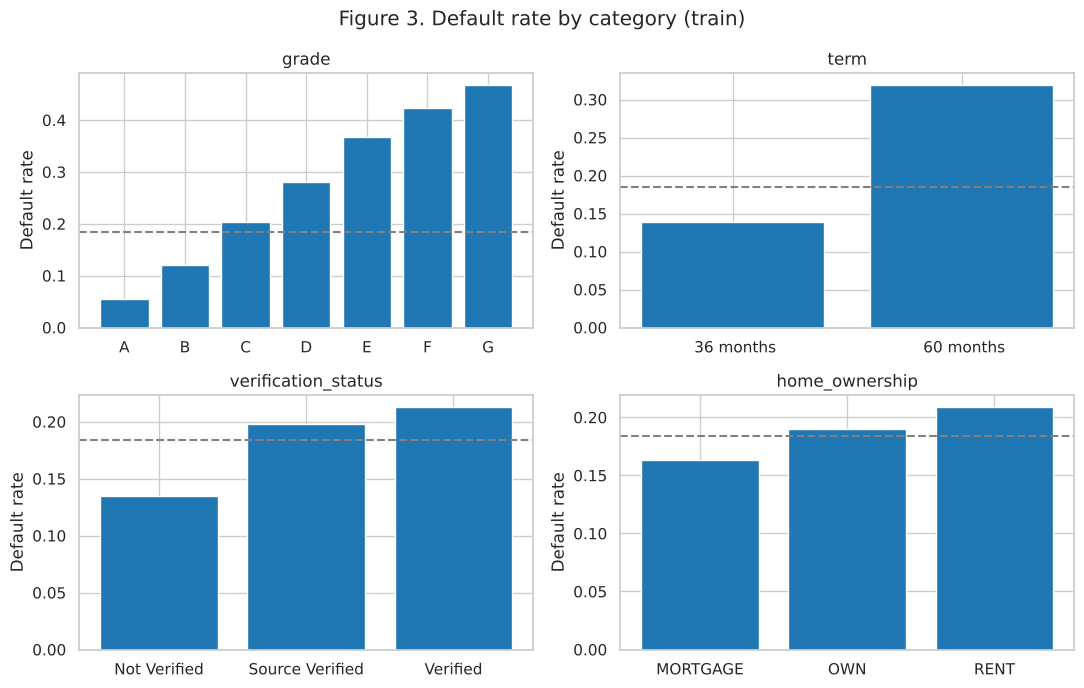

In [17]:
cat_cols = ["grade", "term", "verification_status", "home_ownership"]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    stats = train.groupby(col)["default"].agg(["mean", "size"])
    stats = stats[stats["size"] >= 1000]
    ax.bar(stats.index.astype(str), stats["mean"], color="tab:blue")
    ax.axhline(rate, color="gray", linestyle="--")
    ax.set_title(col)
    ax.set_ylabel("Default rate")
fig.suptitle("Figure 3. Default rate by category (train)")
fig.tight_layout()
save_fig("03_default_by_category")
plt.show()

In [18]:
g = train.groupby("grade")["default"].mean()
t = train.groupby("term")["default"].mean()
v = train.groupby("verification_status")["default"].mean()
print(f"grade: default rate rises from {g.min():.3f} (grade {g.idxmin()}) to {g.max():.3f} (grade {g.idxmax()}) "
      f"- a factor of {g.max()/g.min():.1f}.")
print(f"term: {t.idxmax().strip()} loans default at {t.max():.3f} vs {t.min():.3f} for {t.idxmin().strip()}.")
print("verification_status:", ", ".join(f"{k} {x:.3f}" for k, x in v.items()),
      f"(verified loans default {'more' if v['Verified'] > v['Not Verified'] else 'less'} - we do not test why).")
print("-> Lending Club's own grade already separates risky from safe loans strongly. "
      "That is why it is the baseline to beat (B1 in notebook 03).")

grade: default rate rises from 0.056 (grade A) to 0.467 (grade G) - a factor of 8.4.
term: 60 months loans default at 0.319 vs 0.139 for 36 months.
verification_status: Not Verified 0.134, Source Verified 0.198, Verified 0.213 (verified loans default more - we do not test why).
-> Lending Club's own grade already separates risky from safe loans strongly. That is why it is the baseline to beat (B1 in notebook 03).


**Figure 4.** Default rate for each *tenth* (decile) of six numeric columns. A line that slopes means the column carries signal; a flat line means little.

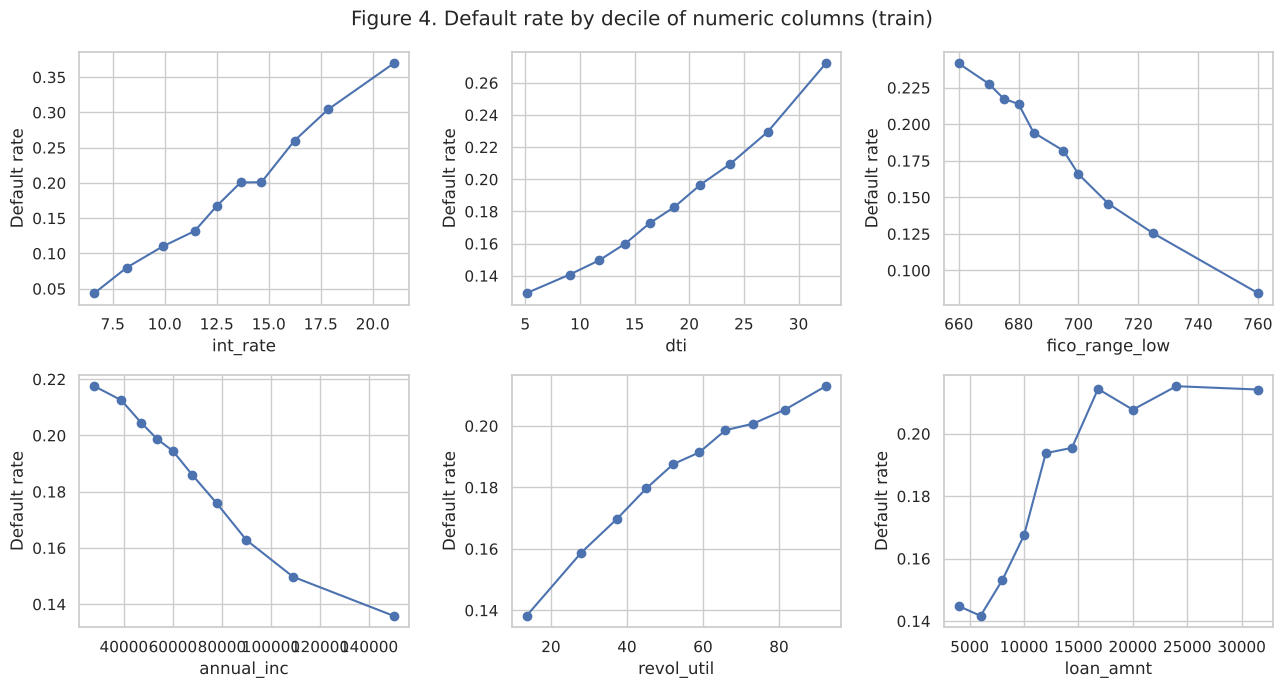

In [19]:
num_cols = ["int_rate", "dti", "fico_range_low", "annual_inc", "revol_util", "loan_amnt"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
decile_range = {}
for ax, col in zip(axes.ravel(), num_cols):
    bins = pd.qcut(train[col], 10, duplicates="drop")
    stats = train.groupby(bins, observed=True).agg(rate=("default", "mean"), mid=(col, "median"))
    ax.plot(stats["mid"], stats["rate"], marker="o")
    ax.set_xlabel(col)
    ax.set_ylabel("Default rate")
    decile_range[col] = (stats["rate"].iloc[0], stats["rate"].iloc[-1])
fig.suptitle("Figure 4. Default rate by decile of numeric columns (train)")
fig.tight_layout()
save_fig("04_default_by_numeric_decile")
plt.show()

In [20]:
for col, (low, high) in decile_range.items():
    direction = "rises" if high > low else "falls"
    print(f"{col:15s} default rate {direction} from {low:.3f} (lowest decile) to {high:.3f} (highest decile)")
flat = [c for c, (lo, hi) in decile_range.items() if abs(hi - lo) < 0.03]
print(f"Columns whose default rate barely changes (< 0.03 between lowest and highest decile): {flat if flat else 'none'}.")
print("Action -> every column shows a slope, so none is dropped at this stage; the model decides how much each matters.")

int_rate        default rate rises from 0.044 (lowest decile) to 0.369 (highest decile)
dti             default rate rises from 0.129 (lowest decile) to 0.272 (highest decile)
fico_range_low  default rate falls from 0.242 (lowest decile) to 0.085 (highest decile)
annual_inc      default rate falls from 0.218 (lowest decile) to 0.136 (highest decile)
revol_util      default rate rises from 0.138 (lowest decile) to 0.213 (highest decile)
loan_amnt       default rate rises from 0.145 (lowest decile) to 0.214 (highest decile)
Columns whose default rate barely changes (< 0.03 between lowest and highest decile): none.
Action -> every column shows a slope, so none is dropped at this stage; the model decides how much each matters.


### 5.3 Do any columns say the same thing twice?

**Figure 5.** Correlation between numeric columns (training rows). Values near +1 or -1 mean two columns carry nearly the same information.

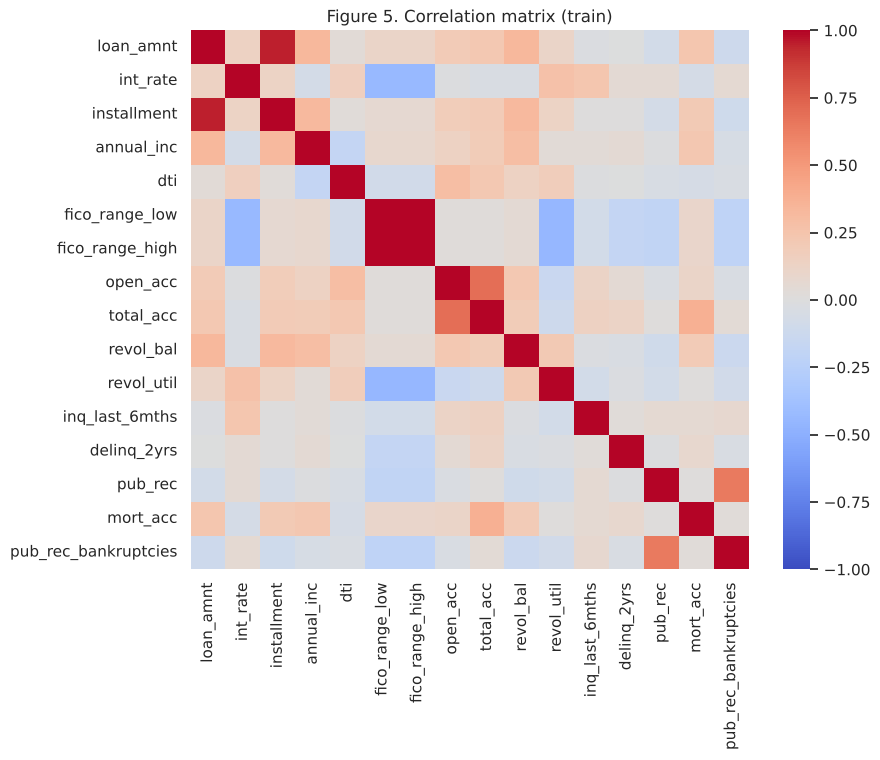

In [21]:
corr_cols = ["loan_amnt", "int_rate", "installment", "annual_inc", "dti", "fico_range_low", "fico_range_high",
             "open_acc", "total_acc", "revol_bal", "revol_util", "inq_last_6mths", "delinq_2yrs", "pub_rec",
             "mort_acc", "pub_rec_bankruptcies"]
corr = train[corr_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Figure 5. Correlation matrix (train)")
save_fig("05_correlation")
plt.show()

In [22]:
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
top = pairs.abs().sort_values(ascending=False).head(5)
print("Five most correlated pairs:")
for (a, b), value in top.items():
    print(f"  {a} & {b}: {pairs[(a, b)]:+.3f}")
print("Action -> the two FICO columns are one signal, so we average them into one feature (step 7). "
      "Other correlated pairs are kept; logistic regression in notebook 03 uses sklearn's default L2 penalty.")

Five most correlated pairs:
  fico_range_low & fico_range_high: +1.000
  loan_amnt & installment: +0.952
  open_acc & total_acc: +0.692
  pub_rec & pub_rec_bankruptcies: +0.646
  fico_range_low & revol_util: -0.445
Action -> the two FICO columns are one signal, so we average them into one feature (step 7). Other correlated pairs are kept; logistic regression in notebook 03 uses sklearn's default L2 penalty.


## Step 6 - Logic checks, cleaning, missing values

We look for impossible values and decide a fix. Only **fixed, row-by-row rules** are applied here (the same rule for train and test). Anything that must *learn* a number, such as filling a gap with the median, is left to the model pipeline in notebook 03.

**Table 5.** Logic checks on training rows.

In [23]:
checks = pd.Series({
    "annual_inc <= 0":                         (train["annual_inc"] <= 0).sum(),
    "dti < 0":                                 (train["dti"] < 0).sum(),
    "dti > 100":                               (train["dti"] > 100).sum(),
    "revol_util > 100":                        (train["revol_util"] > 100).sum(),
    "revol_util > 150":                        (train["revol_util"] > 150).sum(),
    "fico_range_low > fico_range_high":        (train["fico_range_low"] > train["fico_range_high"]).sum(),
    "first credit line after loan issue":      (pd.to_datetime(train["earliest_cr_line"], format="%b-%Y") > train["issue_d"]).sum(),
    "loan_amnt <= 0":                          (train["loan_amnt"] <= 0).sum(),
    "duplicated id":                           df["id"].duplicated().sum(),
}, name="rows_violating")
checks.to_frame()

,rows_violating
annual_inc <= 0,2
dti < 0,0
dti > 100,8
revol_util > 100,3075
revol_util > 150,13
fico_range_low > fico_range_high,0
first credit line after loan issue,0
loan_amnt <= 0,0
duplicated id,0


**What we do about each problem**

| Finding | Decision |
|---|---|
| `annual_inc <= 0`, `dti` outside 0-100 | Impossible values; set to missing (the pipeline fills them later) |
| `revol_util` between 100 and 150 | Possible (balance over the limit); keep |
| `revol_util > 150` | Extreme values; cap at 150 (a fixed number, not learned from data) |
| Other checks | Nothing to fix if the table shows 0 |

In [24]:
df.loc[df["annual_inc"] <= 0, "annual_inc"] = np.nan
df.loc[(df["dti"] < 0) | (df["dti"] > 100), "dti"] = np.nan
df["revol_util"] = df["revol_util"].clip(upper=150)
df = df.drop_duplicates(subset="id")

train = df[df["split"] == "train"]
test = df[df["split"] == "test"]
print(f"After cleaning: train {len(train):,} rows, test {len(test):,} rows")

After cleaning: train 826,604 rows, test 518,706 rows


### 6.1 Missing values

**Table 6.** Share of missing values per column in the **training rows** (only columns with some missing).

In [25]:
missing = train.isna().mean().sort_values(ascending=False)
missing = missing[missing > 0].to_frame("share_missing")
missing

,share_missing
mort_acc,0.057
emp_length,0.052
pub_rec_bankruptcies,0.001
revol_util,0.001
dti,0.000
annual_inc,0.000


In [26]:
MAX_MISSING = 0.30   # a column missing in more than 30% of training rows would be dropped
too_empty = missing[missing["share_missing"] > MAX_MISSING]
print(f"Largest missing share: {missing['share_missing'].max():.3f} ({missing['share_missing'].idxmax()}).")
print(f"Columns above the {MAX_MISSING:.0%} threshold: {len(too_empty)}.")
print("-> Missing shares are small, so we keep all columns and fill gaps with the training median inside the "
      "model pipeline (notebook 03). The threshold was applied to training rows only.")

Largest missing share: 0.057 (mort_acc).
Columns above the 30% threshold: 0.
-> Missing shares are small, so we keep all columns and fill gaps with the training median inside the model pipeline (notebook 03). The threshold was applied to training rows only.


## Step 7 - Feature engineering

Each new feature is a **fixed, row-by-row formula** (no number is learned), so it is safe to compute on all rows.

**Table 7.** New features and the idea behind each.

| New feature | Formula | Idea |
|---|---|---|
| `term_months` | text "36 months" -> 36 | Models need numbers, not text |
| `emp_length_years` | "< 1 year" -> 0, "10+ years" -> 10 | Same |
| `fico_avg` | (fico_range_low + fico_range_high) / 2 | The two FICO columns are nearly identical (Figure 5) |
| `credit_history_years` | (issue_d - earliest_cr_line) / 365.25 | Longer credit history may mean lower risk |
| `log_annual_inc`, `log_revol_bal` | log(1 + x) | Income and balance have a long right tail; log tames it |
| `loan_to_income` | loan_amnt / annual_inc | Size of the loan relative to the ability to repay |
| `sub_grade_num` | A1 = 1, A2 = 2, ... G5 = 35 | Turns Lending Club's sub-grade into a number; used **only** for baseline B1 |

In [27]:
df["term_months"] = df["term"].str.extract(r"(\d+)")[0].astype(int)

emp = df["emp_length"].replace({"< 1 year": "0 years"})
df["emp_length_years"] = emp.str.extract(r"(\d+)")[0].astype(float)

df["fico_avg"] = (df["fico_range_low"] + df["fico_range_high"]) / 2

first_credit = pd.to_datetime(df["earliest_cr_line"], format="%b-%Y")
df["credit_history_years"] = (df["issue_d"] - first_credit).dt.days / 365.25

df["log_annual_inc"] = np.log1p(df["annual_inc"])
df["log_revol_bal"] = np.log1p(df["revol_bal"])
df["loan_to_income"] = df["loan_amnt"] / df["annual_inc"]

df["sub_grade_num"] = (df["sub_grade"].str[0].map(lambda g: ord(g) - ord("A")) * 5
                       + df["sub_grade"].str[1].astype(int))

### 7.1 Check that the conversions did what we meant
A conversion that silently goes wrong is a classic bug, so we print the original text next to the new number.

**Table 8.** Original value vs converted value.

In [28]:
print("emp_length -> emp_length_years")
print(df.groupby(df["emp_length"].fillna("(missing)"))["emp_length_years"].first().to_string())
print()
print("term -> term_months:", df.groupby("term")["term_months"].first().to_dict())
print("sub_grade -> sub_grade_num:", df.groupby("sub_grade")["sub_grade_num"].first().iloc[[0, 1, 5, -1]].to_dict())
print()
print("Years of credit history, summary (should be positive):")
print(df["credit_history_years"].describe().round(2).to_string())

emp_length -> emp_length_years
emp_length
(missing)      NaN
1 year       1.000
10+ years   10.000
2 years      2.000
3 years      3.000
4 years      4.000
5 years      5.000
6 years      6.000
7 years      7.000
8 years      8.000
9 years      9.000
< 1 year     0.000

term -> term_months: {' 36 months': 36, ' 60 months': 60}


sub_grade -> sub_grade_num: {'A1': 1, 'A2': 2, 'B1': 6, 'G5': 35}

Years of credit history, summary (should be positive):
count   1,345,310.000
mean           16.260
std             7.510
min             3.000
25%            11.240
50%            14.750
75%            20.000
max            83.250


### 7.2 Do the new features carry signal?
We compare each new feature with the raw column it came from, again by single-column ROC-AUC on **training rows**. A new feature that is no better than its source is not worth the extra complexity.

**Table 9.** Single-column ROC-AUC, raw vs engineered (training rows).

In [29]:
train = df[df["split"] == "train"]

def auc_alone_of(col):
    values = train[col].fillna(train[col].median())
    auc = roc_auc_score(train["default"], values)
    return max(auc, 1 - auc)

pairs = [("fico_range_low", "fico_avg"),
         ("annual_inc", "log_annual_inc"),
         ("revol_bal", "log_revol_bal"),
         ("loan_amnt", "loan_to_income"),
         ("earliest_cr_line_year", "credit_history_years")]
train = train.assign(earliest_cr_line_year=pd.to_datetime(train["earliest_cr_line"], format="%b-%Y").dt.year)
table = pd.DataFrame([(raw_col, auc_alone_of(raw_col), new_col, auc_alone_of(new_col)) for raw_col, new_col in pairs],
                     columns=["raw_column", "raw_auc", "new_feature", "new_auc"])
table["change"] = table["new_auc"] - table["raw_auc"]
table

,raw_column,raw_auc,new_feature,new_auc,change
0,fico_range_low,0.591,fico_avg,0.591,0.000
1,annual_inc,0.549,log_annual_inc,0.549,0.000
2,revol_bal,0.508,log_revol_bal,0.508,0.000
3,loan_amnt,0.550,loan_to_income,0.602,0.051
4,earliest_cr_line_year,0.535,credit_history_years,0.527,-0.007


In [30]:
for _, r in table.iterrows():
    verdict = "better" if r["change"] > 0.001 else ("same" if abs(r["change"]) <= 0.001 else "worse")
    print(f"{r['new_feature']:22s} AUC {r['new_auc']:.3f} vs {r['raw_column']} {r['raw_auc']:.3f} -> {verdict}")
print()
print("Single-column AUC is only a rough check; the real test is whether a feature helps the model (permutation importance, notebook 03 section 10).")
print("Note: log() never changes AUC for a single column (it keeps the order of values), so log_annual_inc and "
      "log_revol_bal equal their raw columns here by construction. We keep them because they help models that "
      "assume a bell-shaped input, such as logistic regression.")

fico_avg               AUC 0.591 vs fico_range_low 0.591 -> same
log_annual_inc         AUC 0.549 vs annual_inc 0.549 -> same
log_revol_bal          AUC 0.508 vs revol_bal 0.508 -> same
loan_to_income         AUC 0.602 vs loan_amnt 0.550 -> better
credit_history_years   AUC 0.527 vs earliest_cr_line_year 0.535 -> worse

Single-column AUC is only a rough check; the real test is whether a feature helps the model (permutation importance, notebook 03 section 10).
Note: log() never changes AUC for a single column (it keeps the order of values), so log_annual_inc and log_revol_bal equal their raw columns here by construction. We keep them because they help models that assume a bell-shaped input, such as logistic regression.


## Hand-off to notebook 03
We save the final table and the lists of numeric and categorical features. Raw text columns that have been converted are left out.

In [31]:
NUMERIC_FEATURES = ["loan_amnt", "int_rate", "installment", "term_months", "emp_length_years", "dti",
                    "delinq_2yrs", "fico_avg", "inq_last_6mths", "open_acc", "pub_rec", "revol_util",
                    "total_acc", "mort_acc", "pub_rec_bankruptcies", "credit_history_years",
                    "log_annual_inc", "log_revol_bal", "loan_to_income"]
CATEGORICAL_FEATURES = ["grade", "home_ownership", "verification_status", "purpose", "application_type"]
META = ["id", "issue_d", "split", "default", "sub_grade_num"]

final = df[META + NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
final[NUMERIC_FEATURES] = final[NUMERIC_FEATURES].astype(float)   # one dtype for every numeric feature
final.to_parquet(CLEAN_FILE, index=False)
FEATURES_FILE.write_text(json.dumps({"numeric": NUMERIC_FEATURES, "categorical": CATEGORICAL_FEATURES}, indent=2))

print("Saved:", CLEAN_FILE, final.shape)
print("Numeric features:", len(NUMERIC_FEATURES), "| categorical features:", len(CATEGORICAL_FEATURES))
print("Rows per split:", final["split"].value_counts().to_dict())

Saved: ../data/processed/clean.parquet (1345310, 29)
Numeric features: 19 | categorical features: 5
Rows per split: {'train': 826604, 'test': 518706}
